# Support Vector Machines - Exercise 1

In this exercise, we'll be using support vector machines (SVMs) to build a spam classifier.  We'll start with SVMs on some simple 2D data sets to see how they work.  Then we'll do some pre-processing work on a set of raw emails and build a classifier on the processed emails using a SVM to determine if they are spam or not.

The first thing we're going to do is look at a simple 2-dimensional data set and see how a linear SVM works on the data set for varying values of C (similar to the regularization term in linear/logistic regression).  Let's load the data.
## Exercise 1
#### 1. Load libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#### 2. Load data
Load the file *ejer_1_data1.mat*. Find the way for loading this kind of file. **scipy.io.loadmat**

In [2]:
from scipy.io import loadmat

data1 = loadmat('./data/ejer_1_data1.mat')
print(data1)

{'__header__': b'MATLAB 5.0 MAT-file, Platform: GLNXA64, Created on: Sun Nov 13 14:28:43 2011', '__version__': '1.0', '__globals__': [], 'X': array([[1.9643  , 4.5957  ],
       [2.2753  , 3.8589  ],
       [2.9781  , 4.5651  ],
       [2.932   , 3.5519  ],
       [3.5772  , 2.856   ],
       [4.015   , 3.1937  ],
       [3.3814  , 3.4291  ],
       [3.9113  , 4.1761  ],
       [2.7822  , 4.0431  ],
       [2.5518  , 4.6162  ],
       [3.3698  , 3.9101  ],
       [3.1048  , 3.0709  ],
       [1.9182  , 4.0534  ],
       [2.2638  , 4.3706  ],
       [2.6555  , 3.5008  ],
       [3.1855  , 4.2888  ],
       [3.6579  , 3.8692  ],
       [3.9113  , 3.4291  ],
       [3.6002  , 3.1221  ],
       [3.0357  , 3.3165  ],
       [1.5841  , 3.3575  ],
       [2.0103  , 3.2039  ],
       [1.9527  , 2.7843  ],
       [2.2753  , 2.7127  ],
       [2.3099  , 2.9584  ],
       [2.8283  , 2.6309  ],
       [3.0473  , 2.2931  ],
       [2.4827  , 2.0373  ],
       [2.5057  , 2.3853  ],
       [1.8721  ,

#### 3. Create a DataFrame with the features and target

In [3]:
df1 = pd.DataFrame(data1['X'], columns=['Feature_1', 'Feature_2'])
df1['Target'] = data1['y']
df1.head()

,Feature_1,Feature_2,Target
0,1.9643,4.5957,1
1,2.2753,3.8589,1
2,2.9781,4.5651,1
3,2.9320,3.5519,1
4,3.5772,2.8560,1


#### 4. Plot a scatterplot with the data

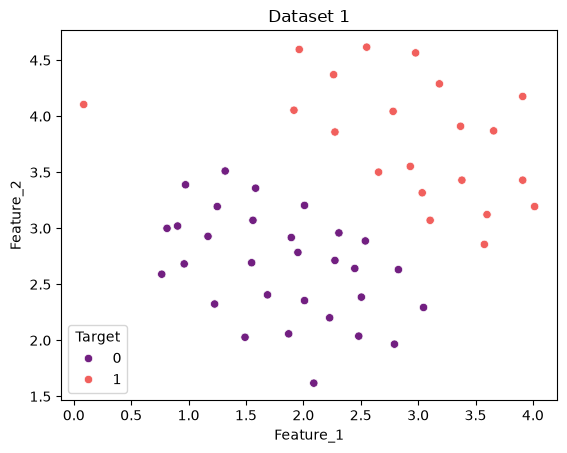

In [4]:
sns.scatterplot(data=df1, x='Feature_1', y='Feature_2', hue='Target', palette='magma')
plt.title('Dataset 1')
plt.show()

Notice that there is one outlier positive example that sits apart from the others.  The classes are still linearly separable but it's a very tight fit.  We're going to train a linear support vector machine to learn the class boundary.

#### 5. LinearSVC
Declare a Linear SVC with the hyperparamenters:

```Python
LinearSVC(C=1, loss='hinge', max_iter=10000)
```

In [5]:
from sklearn.svm import LinearSVC

svc1 = LinearSVC(C=1, loss='hinge', max_iter=10000)


#### 6. Try the performance (score)
For the first experiment we'll use C=1 and see how it performs.

In [6]:
X1 = df1[['Feature_1', 'Feature_2']]
y1 = df1['Target']

svc1.fit(X1, y1)

score1 = svc1.score(X1, y1)
print(f'Score con C=1: {score1:.4f}')

Score con C=1: 0.9804


It appears that it mis-classified the outlier.

#### 7. Increase the value of C until you get a perfect classifier

In [7]:
svc2 = LinearSVC(C=370, loss='hinge', max_iter=100000)

svc2.fit(X1, y1)

score2 = svc2.score(X1, y1)
print(f'Score con C=370: {score2:.4f}')

Score con C=370: 1.0000


This time we got a perfect classification of the training data, however by increasing the value of C we've created a decision boundary that is no longer a natural fit for the data.  We can visualize this by looking at the confidence level for each class prediction, which is a function of the point's distance from the hyperplane.

#### 8. Plot Decission Function
Get the `decision_function()` output for the first model. Plot a scatterplot with X1, X2 and a range of colors based on `decision_function()`

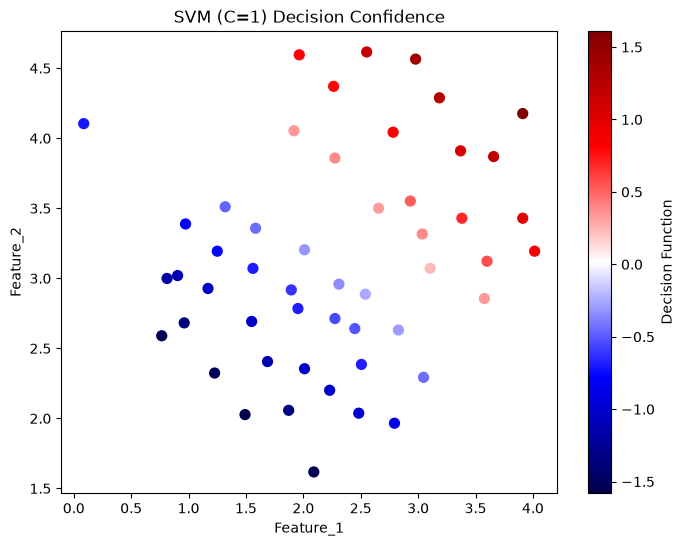

In [8]:
df1['SVM_1_Confidence'] = svc1.decision_function(X1)

plt.figure(figsize=(8, 6))
plt.scatter(df1['Feature_1'], df1['Feature_2'], s=50, c=df1['SVM_1_Confidence'], cmap='seismic')
plt.colorbar(label='Decision Function')
plt.title('SVM (C=1) Decision Confidence')
plt.xlabel('Feature_1')
plt.ylabel('Feature_2')
plt.show()


#### 9. Do the same with the second model

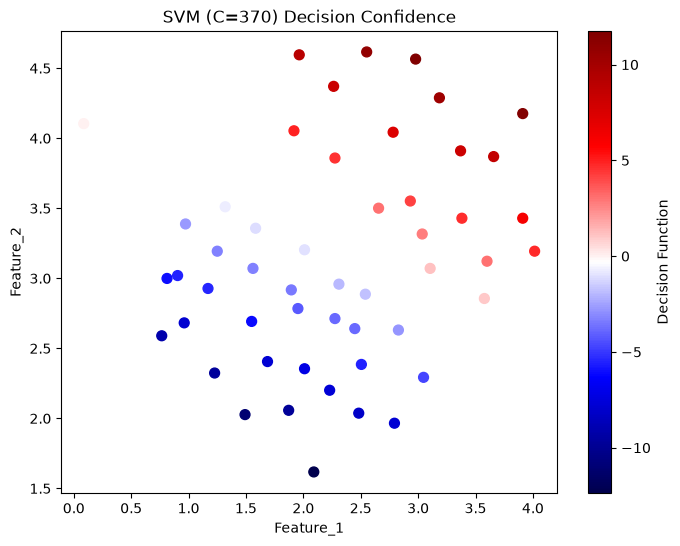

In [9]:
df1['SVM_2_Confidence'] = svc2.decision_function(X1)

plt.figure(figsize=(8, 6))
plt.scatter(df1['Feature_1'], df1['Feature_2'], s=50, c=df1['SVM_2_Confidence'], cmap='seismic')
plt.colorbar(label='Decision Function')
plt.title('SVM (C=370) Decision Confidence')
plt.xlabel('Feature_1')
plt.ylabel('Feature_2')
plt.show()

https://www.svm-tutorial.com/2015/06/svm-understanding-math-part-3/

#### 1. Load the data `ejer_1_data2.mat`

In [10]:
data2 = loadmat('./data/ejer_1_data2.mat')

#### 2. Create a DataFrame with the features and target

In [11]:
df2 = pd.DataFrame(data2['X'], columns=['Feature_1', 'Feature_2'])
df2['Target'] = data2['y']

#### 3. Plot a scatterplot with the data

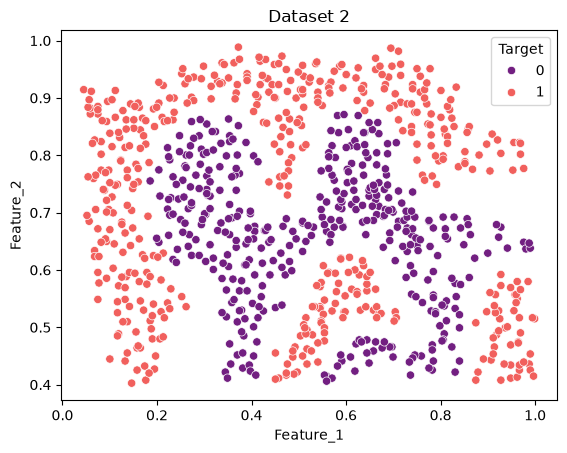

In [12]:
sns.scatterplot(data=df2, x='Feature_1', y='Feature_2', hue='Target', palette='magma')
plt.title('Dataset 2')
plt.show()

For this data set we'll build a support vector machine classifier using the built-in RBF kernel and examine its accuracy on the training data.  To visualize the decision boundary, this time we'll shade the points based on the predicted probability that the instance has a negative class label.  We'll see from the result that it gets most of them right.

#### 4. Declare a SVC with this hyperparameters
```Python
SVC(C=100, gamma=10, probability=True)
```


In [13]:
X2 = df2[['Feature_1', 'Feature_2']]
y2 = df2['Target']

In [14]:
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV

base_svc = SVC(C=100, gamma=10)
svc_rbf = CalibratedClassifierCV(base_svc, ensemble=False)

#### 5. Fit the classifier and get the score

In [15]:
svc_rbf.fit(X2, y2)
print(f'Score RBF: {svc_rbf.score(X2, y2):.4f}')

Score RBF: 0.9409


#### 6. Plot the scatter plot and probability of predicting 0 with a [sequential color](https://matplotlib.org/3.1.1/tutorials/colors/colormaps.html)

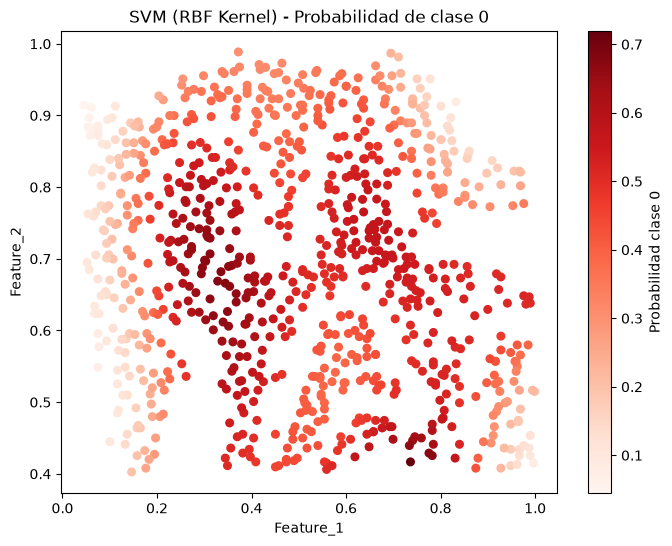

In [16]:
df2['Probability_0'] = svc_rbf.predict_proba(X2)[:, 0]

plt.figure(figsize=(8, 6))
plt.scatter(df2['Feature_1'], df2['Feature_2'], s=30, c=df2['Probability_0'], cmap='Reds')
plt.colorbar(label='Probabilidad clase 0')
plt.title('SVM (RBF Kernel) - Probabilidad de clase 0')
plt.xlabel('Feature_1')
plt.ylabel('Feature_2')
plt.show()